# Fisheye Visual Odometry with Homography

This notebook streamlines the existing pose recovery workflow into three focused:

- Undistort fisheye frames to verify calibration quality
- Track and filter feature correspondences between rectified frames
- Integrate homography-derived motions into a relative trajectory and plot the path

In [1]:
import json
from dataclasses import dataclass
from pathlib import Path
from typing import List, Optional, Tuple

import cv2 as cv
import matplotlib.pyplot as plt
import numpy as np
from pose_helpers import (
    analyze_trajectory,
    plot_trajectory,
    write_video_with_trajectory,
    draw_tracks,
    TrajectoryResult,
    TrajectoryVideoWriter,
)

plt.rcParams["figure.figsize"] = (14, 6)
plt.rcParams["font.size"] = 11

In [2]:
# --- Configuration ---
PROJECT_ROOT = Path("./flight")
VIDEO_PATH = PROJECT_ROOT / "recording.mp4"
CALIBRATION_PATH = PROJECT_ROOT / "calibration-params.json"

if not VIDEO_PATH.exists():
    raise FileNotFoundError(VIDEO_PATH)
if not CALIBRATION_PATH.exists():
    raise FileNotFoundError(CALIBRATION_PATH)

print(f"Video: {VIDEO_PATH}")
print(f"Calibration: {CALIBRATION_PATH}")

Video: flight/recording.mp4
Calibration: flight/calibration-params.json


In [3]:
# --- Calibration & undistortion helpers ---
def load_camera_intrinsics(
    json_path: Path,
) -> Tuple[np.ndarray, np.ndarray, Tuple[int, int]]:
    """Return camera matrix K, distortion vector D, and image size."""
    with json_path.open("r", encoding="utf-8") as camera_conf_file:
        camera_conf = json.load(camera_conf_file)["cameras"][0]

        distortion_coefs = np.array(
            camera_conf["distortionCoefficients"], dtype=np.float64
        )

        camera_intrinsics = np.array(
            [
                [camera_conf["focalLengthX"], 0, camera_conf["principalPointX"]],
                [0, camera_conf["focalLengthY"], camera_conf["principalPointY"]],
                [0, 0, 1],
            ]
        )

        image_size = camera_conf["imageWidth"], camera_conf["imageHeight"]

        return camera_intrinsics, distortion_coefs, image_size


def create_fisheye_rectification_maps(
    K: np.ndarray,
    D: np.ndarray,
    image_size: Tuple[int, int],
) -> Tuple[np.ndarray, np.ndarray, np.ndarray]:
    """Pre-compute undistortion maps for faster remapping during VO."""
    K_new = cv.fisheye.estimateNewCameraMatrixForUndistortRectify(
        K=K, D=D, image_size=image_size, R=np.eye(3)
    )
    map1, map2 = cv.fisheye.initUndistortRectifyMap(
        D=D, K=K, R=np.eye(3), P=K_new, size=image_size, m1type=cv.CV_32FC1
    )

    return K_new, map1, map2


def undistort_with_maps(
    frame: np.ndarray, map1: np.ndarray, map2: np.ndarray
) -> np.ndarray:
    """Apply pre-computed undistortion maps to a frame."""
    return cv.remap(frame, map1, map2, interpolation=cv.INTER_LINEAR)


def read_frame(video_path: Path, index: int) -> np.ndarray:
    cap = cv.VideoCapture(str(video_path))
    if not cap.isOpened():
        raise RuntimeError(f"Cannot open {video_path}")
    cap.set(cv.CAP_PROP_POS_FRAMES, index)
    ok, frame = cap.read()
    cap.release()
    if not ok:
        raise RuntimeError(f"Failed to read frame {index}")
    return frame


def read_frame_pair(
    video_path: Path, base_index: int, offset: int
) -> Tuple[np.ndarray, np.ndarray]:
    first = read_frame(video_path, base_index)
    second = read_frame(video_path, base_index + offset)
    return first, second

In [4]:
K, D, image_size = load_camera_intrinsics(CALIBRATION_PATH)
print("Camera intrinsics loaded")
print(f"Image size   : {image_size[0]} x {image_size[1]}")
print(f"Focal lengths: fx={K[0, 0]:.2f}, fy={K[1, 1]:.2f}")
print(f"Principal pt : cx={K[0, 2]:.2f}, cy={K[1, 2]:.2f}")
print(f"Distortion   : {D.ravel()}")

NEW_K, undistort_map1, undistort_map2 = create_fisheye_rectification_maps(
    K, D, image_size
)
print("Rectification maps prepared.")

Camera intrinsics loaded
Image size   : 1920 x 1080
Focal lengths: fx=590.07, fy=589.52
Principal pt : cx=1015.07, cy=571.36
Distortion   : [-0.03678765  0.00404803 -0.00777366  0.00206872]
Rectification maps prepared.


## 1. Undistortion Check

Rectify a representative frame with the fisheye calibration to confirm that straight edges appear linear and the field of view remains sufficient.

Raw frame shape        : (1080, 1920, 3)
Undistorted frame shape: (1080, 1920, 3)


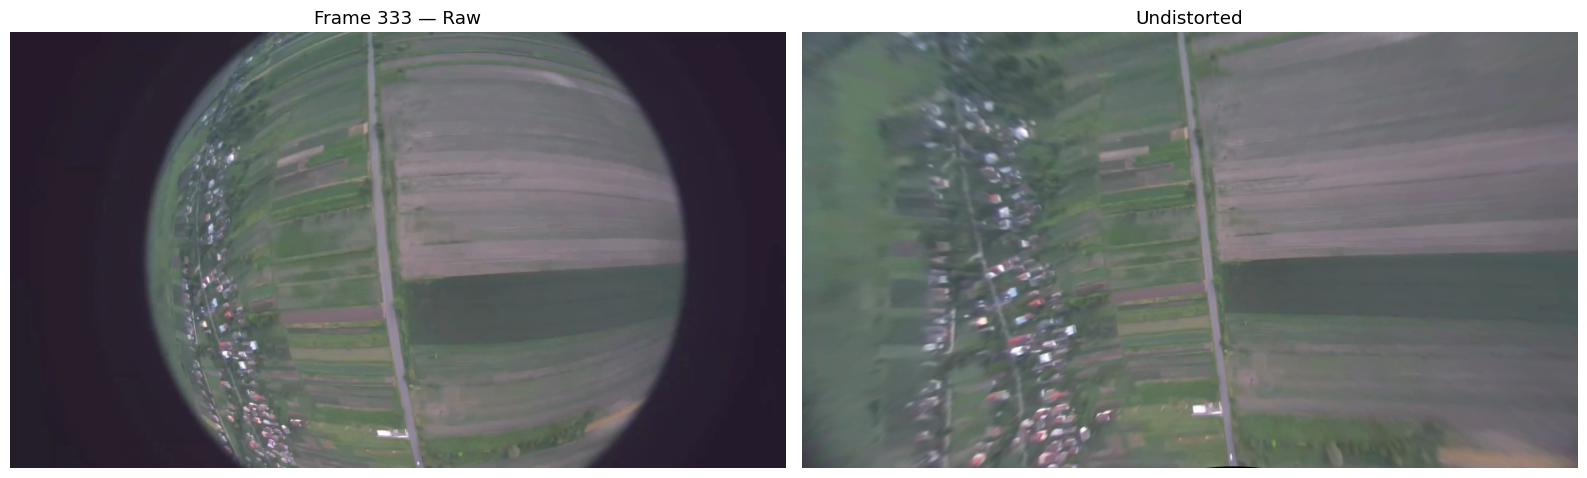

In [5]:
sample_frame_index = 333
raw_frame = read_frame(VIDEO_PATH, sample_frame_index)
undistorted_frame = undistort_with_maps(raw_frame, undistort_map1, undistort_map2)

print(f"Raw frame shape        : {raw_frame.shape}")
print(f"Undistorted frame shape: {undistorted_frame.shape}")

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
axes[0].imshow(cv.cvtColor(raw_frame, cv.COLOR_BGR2RGB))
axes[0].set_title(f"Frame {sample_frame_index} — Raw")
axes[0].axis("off")

axes[1].imshow(cv.cvtColor(undistorted_frame, cv.COLOR_BGR2RGB))
axes[1].set_title("Undistorted")
axes[1].axis("off")

plt.tight_layout()
plt.show()

## 2. Feature Detection and Tracking

Use Shi–Tomasi corners (`cv.goodFeaturesToTrack`) for feature detection and Lucas–Kanade optical flow on the undistorted frames. You're encouraged to experiment with other feature detection algorithms (SIFT, ORB, etc)

In [6]:
def good_features(
    gray: np.ndarray,
    max_corners: int = 3000,
    grid_rows: int = 8,
    grid_cols: int = 8,
) -> Optional[np.ndarray]:
    """
    Uniformly sample features  across the image by dividing it into a grid
    and extracting up to max_corners features distributed among cells.
    """

    h, w = gray.shape
    dx, dy = h // grid_rows, w // grid_cols

    max_corners_per_grid = max_corners // (grid_rows * grid_cols)

    features = []
    for i in range(grid_rows):
        for j in range(grid_cols):
            start_x, start_y = i * dx, j * dy
            end_x, end_y = start_x + dx, start_y + dy

            curr_cell_features = cv.goodFeaturesToTrack(
                image=gray[start_x:end_x, start_y:end_y],
                maxCorners=max_corners_per_grid,
                qualityLevel=0.01,
                minDistance=10,
            )

            if curr_cell_features is not None:
                curr_cell_features[:, 0, 0] += start_y
                curr_cell_features[:, 0, 1] += start_x

                features.append(curr_cell_features)

    return np.concat(features)


def compute_good_feature_tracks(
    gray1: np.ndarray,
    gray2: np.ndarray,
    prev_pts: Optional[np.ndarray] = None,
    max_corners: int = 3000,
    lk_params: Optional[dict] = None,
) -> Tuple[Optional[np.ndarray], Optional[np.ndarray], Optional[np.ndarray]]:
    """
    Run Lucas-Kanade tracking on Shi-Tomasi features between two grayscale frames.

    Returns:
        prev_pts: points on the first frame with shape (N, 1, 2) or None
        curr_pts: corresponding points on the second frame with shape (N, 1, 2) or None
        status_mask: boolean array marking which points were successfully tracked
    """

    lk_params = (
        {
            "winSize": (21, 21),
            "maxLevel": 3,
            "criteria": (cv.TERM_CRITERIA_EPS | cv.TERM_CRITERIA_COUNT, 30, 0.01),
        }
        if lk_params is None
        else lk_params
    )
    prev_pts = (
        good_features(gray=gray1, max_corners=max_corners)
        if prev_pts is None
        else prev_pts
    )

    curr_pts, status, err = cv.calcOpticalFlowPyrLK(
        prevImg=gray1, nextImg=gray2, prevPts=prev_pts, nextPts=None, **lk_params
    )

    return prev_pts, curr_pts, status.flatten()


def track_good_features(
    img1_bgr: np.ndarray,
    img2_bgr: np.ndarray,
    prev_pts: np.ndarray | None = None,
    max_corners: int = 3000,
) -> Tuple[np.ndarray, np.ndarray, np.ndarray, np.ndarray]:
    """Shi-Tomasi + LK. Green = tracked correspondences, red dots = lost tracks in img1."""
    gray1 = cv.cvtColor(img1_bgr, cv.COLOR_BGR2GRAY)
    gray2 = cv.cvtColor(img2_bgr, cv.COLOR_BGR2GRAY)

    prev_pts, curr_pts, status_all = compute_good_feature_tracks(
        gray1, gray2, prev_pts=prev_pts, max_corners=max_corners
    )

    if prev_pts is None or curr_pts is None or status_all is None:
        raise RuntimeError("Feature tracking failed")

    status_all = np.asarray(status_all, dtype=bool)
    pts1 = prev_pts.reshape(-1, 2)
    pts2 = curr_pts.reshape(-1, 2)

    good_prev = pts1[status_all]
    good_curr = pts2[status_all]
    lost_prev = pts1[~status_all]

    h1, w1 = img1_bgr.shape[:2]
    h2, w2 = img2_bgr.shape[:2]
    vis = np.zeros((max(h1, h2), w1 + w2, 3), dtype=np.uint8)
    vis[:h1, :w1] = img1_bgr
    vis[:h2, w1 : w1 + w2] = img2_bgr

    # draw tracked correspondences (green)
    for (x1, y1), (x2, y2) in zip(good_prev, good_curr):
        x1, y1, x2, y2 = map(lambda v: int(np.round(v).item()), (x1, y1, x2, y2))
        cv.line(vis, (x1, y1), (x2 + w1, y2), (0, 255, 0), 1, cv.LINE_AA)
        cv.circle(vis, (x1, y1), 3, (0, 255, 0), -1, cv.LINE_AA)
        cv.circle(vis, (x2 + w1, y2), 3, (0, 255, 0), -1, cv.LINE_AA)

    # draw lost points (red) on img1
    for x1, y1 in lost_prev:
        x1, y1 = int(np.round(x1).item()), int(np.round(y1).item())
        cv.circle(vis, (x1, y1), 3, (0, 0, 255), -1, cv.LINE_AA)

    vis_rgb = cv.cvtColor(vis, cv.COLOR_BGR2RGB)

    # Return tracked pairs only + status over all initial points
    return pts1, pts2, status_all, vis_rgb

Detected features frame 1: 128
Tracked points frame 2: 112


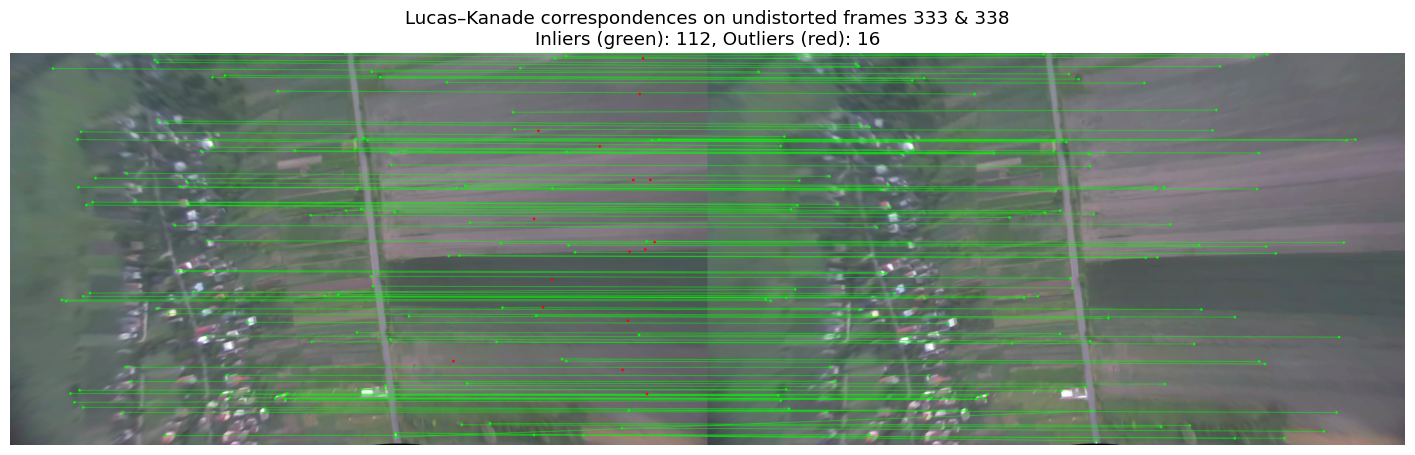

In [7]:
offset_frame = 5
raw_a, raw_b = read_frame_pair(VIDEO_PATH, sample_frame_index, offset_frame)
rect_a = undistort_with_maps(raw_a, undistort_map1, undistort_map2)
rect_b = undistort_with_maps(raw_b, undistort_map1, undistort_map2)

prev_pts, curr_pts, inlier_mask, vis_matches = track_good_features(
    rect_a,
    rect_b,
    max_corners=150,
)

num_tracked = len(prev_pts)
num_inliers = int(inlier_mask.sum())

print(f"Detected features frame 1: {num_tracked}")
print(f"Tracked points frame 2: {num_inliers}")

plt.figure(figsize=(18, 8))
plt.imshow(vis_matches)
plt.title(
    f"Lucas–Kanade correspondences on undistorted frames {sample_frame_index} & {sample_frame_index + offset_frame}\n"
    f"Inliers (green): {num_inliers}, Outliers (red): {num_tracked - num_inliers}"
)
plt.axis("off")
plt.show()

## 3. Homography-Based Trajectory (Fisheye)

Using only feature detections, track corners through the sequence, estimate inter-frame homographies, and pick the motion hypothesis that keeps pose as close as possible to nadir (homework assumption). The accumulated poses form a relative path (scale remains arbitrary).

In [20]:
from tqdm import tqdm


def choose_pose_candidate(
    Rs: List[np.ndarray], ts: List[np.ndarray], normals: List[np.ndarray]
) -> Optional[Tuple[np.ndarray, np.ndarray]]:
    """
    Select the pose (R, t) whose associated normal is closest to nadir ([0, 0, 1])
    and return it.

    Hint: Use cosine similarity to find the best match.
    """

    if normals is None:
        raise ValueError("Normals are not provided")

    expected_normal = np.array([0.0, 0.0, 1.0])

    cos_sim = -1.0
    res_R = Rs[0]
    res_t = ts[0].reshape(-1)
    for R, t, normal in zip(Rs, ts, normals):
        normal = normal.reshape(-1)
        normal_norm = np.linalg.norm(normal)
        if normal_norm > 1e-6:
            normal /= normal_norm

        new_cos_sim = np.dot(normal, expected_normal)

        if new_cos_sim > cos_sim:
            cos_sim = new_cos_sim
            res_R = R
            res_t = t.reshape(-1)

    return res_R, res_t


def recover_homography_trajectory(
    video_path: Path,
    map1: np.ndarray,
    map2: np.ndarray,
    K_rectified: np.ndarray,
    image_size: tuple[int, int] = (1080, 1920),
    min_inliers: int = 60,
    min_points: int = 120,
    max_corners: int = 4000,
    output_video_path: Optional[Path] = None,
    draw_thickness: int = 1,
) -> TrajectoryResult:
    """
    Recover a trajectory from a video using homography-based pose estimation.

    TODO: Implement the homography-based trajectory recovery logic here

    Steps to implement:
    1. Undistort the current frame
    2. Track features from previous frame to current frame
    3. Handle cases where tracking fails (reacquire features if below min_inliers threshold)
    4. Filter tracked points based on status
    5. Check if enough points remain (reacquire features if below min_points threshold)
    6. Compute homography using RANSAC
    7. Check if homography is valid and has enough inliers (min_inliers threshold)
    8. Decompose homography to extract rotation and translation
    9. Update the camera pose (current_R and current_pos)
    10. Store trajectory data (timestamps, positions, inliers, frame_indices)
    11. Write frame with overlay to output video if enabled
    """
    cap = cv.VideoCapture(str(video_path))
    if not cap.isOpened():
        raise RuntimeError(f"Cannot open {video_path}")

    fps = cap.get(cv.CAP_PROP_FPS)
    total_frames = int(cap.get(cv.CAP_PROP_FRAME_COUNT))
    print(f"Video FPS: {fps:.2f}, total frames: {total_frames}")

    ret, prev_raw = cap.read()
    if not ret:
        cap.release()
        raise RuntimeError("Could not read first frame")

    w, h = image_size
    video_writer = TrajectoryVideoWriter(output_video_path, fps, (h, w), draw_thickness)

    # TODO: Find the initial set of features
    prev_frame = undistort_with_maps(prev_raw, map1, map2)
    prev_gray_img = cv.cvtColor(prev_frame, cv.COLOR_BGR2GRAY)
    prev_features = good_features(prev_gray_img, max_corners=max_corners)

    timestamps: List[float] = []
    inliers: List[int] = []
    frame_indices: List[int] = []

    current_R = np.eye(3, dtype=float)
    current_pos = np.zeros(3, dtype=float)
    positions = [current_pos.copy()]

    processed = 0

    with tqdm(total=total_frames, desc="Recovering Homography Trajectory") as pbar:
        while True:
            ret, curr_raw = cap.read()
            if not ret:
                break
            video_writer.increment_frame()
            curr_frame = undistort_with_maps(curr_raw, map1, map2)

            prev_pts, curr_pts, inlier_mask, _ = track_good_features(
                prev_frame,
                curr_frame,
                prev_pts=prev_features,
                max_corners=150,
            )
            num_inliers = inlier_mask.sum()
            num_points = len(curr_pts)

            if num_inliers < min_inliers:
                curr_frame_gray = cv.cvtColor(curr_frame, cv.COLOR_BGR2GRAY)
                prev_features = good_features(curr_frame_gray, max_corners=max_corners)
                prev_frame = curr_frame
                processed += 1

                positions.append(current_pos.copy())
                timestamps.append(cap.get(cv.CAP_PROP_POS_MSEC) / 1000)
                frame_indices.append(processed)
                inliers.append(0)

                video_writer.write_frame_with_overlay(
                    curr_frame,
                    prev_pts,
                    curr_pts,
                    inlier_mask,
                    "Not enough inliers!",
                    (0, 0, 255),
                )
                continue

            timestamps.append(cap.get(cv.CAP_PROP_POS_MSEC) / 1000)
            inliers.append(num_inliers)
            frame_indices.append(processed)

            good_prev = prev_pts[inlier_mask]
            good_curr = curr_pts[inlier_mask]

            H, mask = cv.findHomography(
                srcPoints=good_prev,
                dstPoints=good_curr,
                method=cv.RANSAC,
                ransacReprojThreshold=1,
            )
            if H is not None:
                ransac_inliers = mask.ravel().sum()
                if ransac_inliers > min_inliers:
                    num_solutions, rotations, translations, normals = (
                        cv.decomposeHomographyMat(H, K_rectified)
                    )

                    R, t = choose_pose_candidate(rotations, translations, normals)

                    current_R = R @ current_R
                    current_pos += current_R @ (t)
                    valid_motion = True

            positions.append(current_pos.copy())

            if len(good_curr) < min_points:
                video_writer.write_frame_with_overlay(
                    curr_frame,
                    prev_pts,
                    curr_pts,
                    inlier_mask,
                    "Number of matched features is lower than threshold",
                    (255, 0, 255),
                )
                curr_frame_gray = cv.cvtColor(curr_frame, cv.COLOR_BGR2GRAY)
                prev_features = good_features(curr_frame_gray, max_corners=max_corners)
            else:
                video_writer.write_frame_with_overlay(
                    curr_frame,
                    prev_pts,
                    curr_pts,
                    inlier_mask,
                    "Succesfull matching and homography estimation!",
                    (0, 255, 0),
                )
                prev_features = good_curr

            prev_frame = curr_frame
            processed += 1
            pbar.update(1)

    print(f"Processed {processed} frames, recovered {len(frame_indices)} poses")
    if output_video_path is not None:
        print(f"Wrote overlay video: {output_video_path}")

    return TrajectoryResult(
        timestamps=timestamps,
        positions=np.vstack(positions),
        inliers=inliers,
        frame_indices=frame_indices,
    )

Starting homography-based trajectory recovery...
Video FPS: 19.85, total frames: 3561


Recovering Homography Trajectory: 100%|█████████▉| 3560/3561 [01:02<00:00, 56.52it/s]


Processed 3560 frames, recovered 3560 poses
Wrote overlay video: undistorted_features.mp4


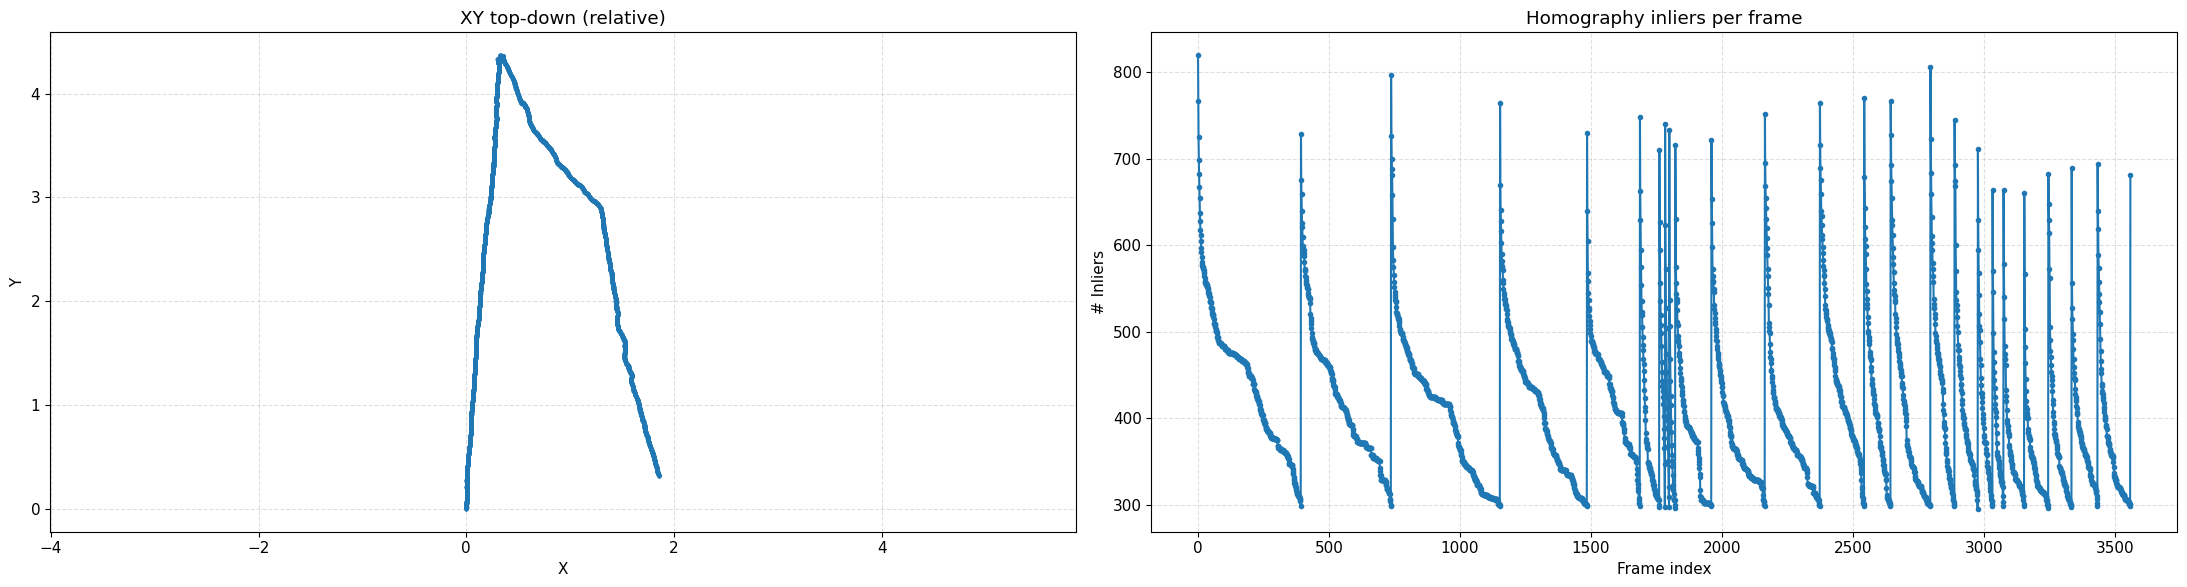

In [21]:
import pathlib

print("Starting homography-based trajectory recovery...")
traj_result = recover_homography_trajectory(
    VIDEO_PATH,
    undistort_map1,
    undistort_map2,
    NEW_K,
    min_inliers=60,
    max_corners=1000,
    min_points=300,
    output_video_path=Path("undistorted_features.mp4"),
)

plot_trajectory(traj_result)


In [18]:
write_video_with_trajectory(
    "undistorted_features.mp4",
    traj_result,
    output_path="trajectory_overlay.mp4",
    stride=1,
)

Writing video with trajectory:  12%|█▏        | 413/3560 [00:17<02:10, 24.08frame/s]


KeyboardInterrupt: 

--- Trajectory Alignment Report ---
Calibrated on first 500 of 3560 overlapping frames.

Similarity Alignment Parameters:
  Scale = 187.8652
  Rotation = 88.59°
  Translation = [-366.93, -293.23] m

Error (Calibration Segment):
  RMS = 1.34 m
  Max = 2.72 m

Error (Full Trajectory):
  RMS = 102.02 m

---------------------------------

Ground truth trajectory length: 1753.63 m
Aligned VO trajectory length:   1863.53 m


/Users/vitya/Documents/3D-CV-homeworks/Optical Flow Assignment /pose_helpers.py:319: RuntimeWarning: divide by zero encountered in matmul
  aligned_positions_xy = (scale * (raw_positions_xy @ rotation.T)) + translation
/Users/vitya/Documents/3D-CV-homeworks/Optical Flow Assignment /pose_helpers.py:319: RuntimeWarning: overflow encountered in matmul
  aligned_positions_xy = (scale * (raw_positions_xy @ rotation.T)) + translation
/Users/vitya/Documents/3D-CV-homeworks/Optical Flow Assignment /pose_helpers.py:319: RuntimeWarning: invalid value encountered in matmul
  aligned_positions_xy = (scale * (raw_positions_xy @ rotation.T)) + translation


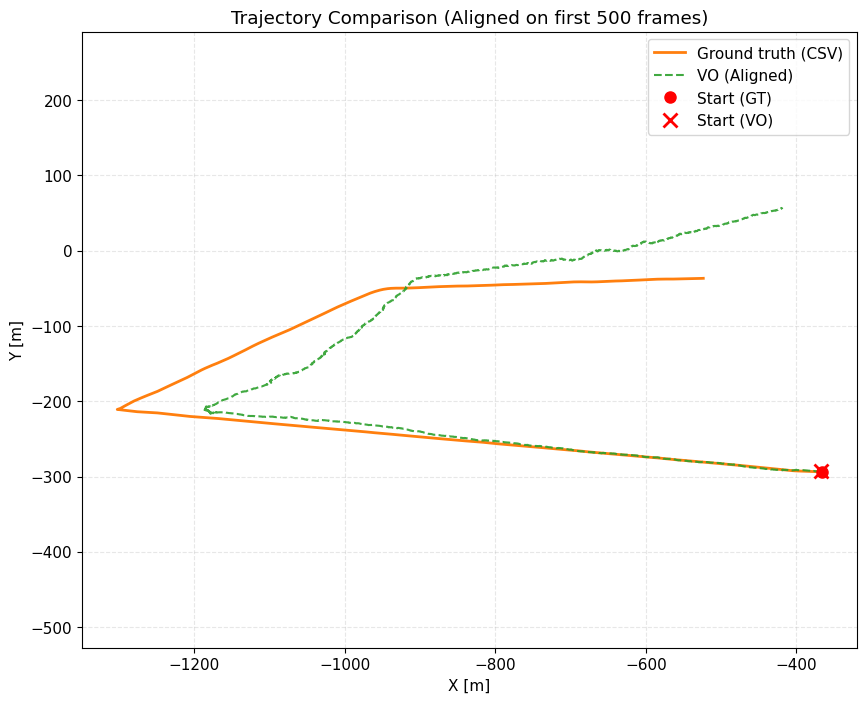

In [23]:
# analyze_trajectory is imported from pose_helpers
analyze_trajectory(traj_result, Path("flight/flight_trajectory_coordinates.csv"))

# Report
For the fisheye undistortion I used basic opencv methods, that estimate new "virtual" camera intrinsics for specific camera distrotion parameters, calculate the mapping to change from initial camera parameters to undistorted and apply the mappings.

For feature extraction and mapping I used Shi-Tomasi corner detector which wath applied to $n\times m$ cells of a frame, for more uniform feature distribution over image. Then I used Lukas-Kanade for feature matching.

For trajectory reconstruction I used pipeline proposed in the homework. Extract and match features, find homography (we assume that we look onto (perpendicularly) a plane) decompose homography into 4 soution and choose the one which plane's normal is the closes to $\begin{bmatrix}0&0&1 \end{bmatrix}^\top$.

Estimated rotation between to camera frames is applied from the left, as I estimate rotation from first view to the second one.
I decided to use parameters proposed as default values in function's definitions as it gives adequate solution, close to the one in homework's description document.

I also noticed, that severe deviation from the real trajectory happens when camera start tilting left-to-right.